# LIDC-IDRI: Exploração e Análise de Nódulos Pulmonares

Abordagem usando `pylidc` para carregar e processar dados de CT scans com anotações de múltiplos radiólogos.

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LIDC-IDRI — Lung Image Database Consortium
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    The reference dataset for lung nodule detection
  </h3>

  <p>
    O LIDC-IDRI é o dataset mais citado em deteção e classificação de nódulos pulmonares. Foi criado por 7 instituições académicas americanas, em colaboração com a <em>Foundation for the National Institutes of Health</em> e a <em>National Cancer Institute</em>.
  </p>

  <p>
    Ao contrário do LNDb- que é de uma única instituição (CHUSJ, Porto) e usa uma metodologia <em>single-blind</em>- o LIDC-IDRI foi anotado por <strong>4 radiotorácicos experientes</strong> em duas fases: uma primeira leitura cega (<em>blinded-read</em>) e uma segunda fase não-cega (<em>unblinded-read</em>), em que cada radiologista teve acesso às marcações anonimizadas dos outros três.
  </p>

  <p>
    Este notebook faz uma análise exploratória inicial do LIDC-IDRI, com o objetivo de extrair uma tabela de nódulos e de identificar as diferenças estruturais face ao LNDb.
  </p>

</div>

## Setup

Importamos as bibliotecas habituais e o `pylidc`, que lê os XMLs oficiais do LIDC e constrói uma base de dados SQLite local. Isto é essencial porque os XMLs originais são difíceis de consultar diretamente.

In [1]:
import numpy as np

# Compatibilidade do pylidc com NumPy >= 1.24: só repomos o alias removido (np.int).
# NÃO sobrescrever np.bool/np.float: no NumPy 2 já existem e o resto do NumPy depende deles.
if not hasattr(np, "int"):
    np.int = int

import pylidc as pl

/home/anasofia/labiacd/mass_detect/.venv/lib/python3.10/site-packages/pylidc/__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


In [2]:
import pylidc as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

# Configuração do pylidc (ver .pylidcrc)
# O pylidc lê o ficheiro ~/.pylidcrc, que tem de apontar para a pasta dos XMLs
#print("Pylidc config:", pl.config)

# Quantos scans/pacientes temos disponíveis?
n_scans = pl.query(pl.Scan).count()
n_patients = pl.query(pl.Scan.patient_id).distinct().count()
n_annotations = pl.query(pl.Annotation).count()

print(f"Scans (séries de TC): {n_scans}")
print(f"Pacientes únicos:     {n_patients}")
print(f"Anotações totais:     {n_annotations}")

"""Silencia os prints do pylidc durante o clustering, que são muitos e não são úteis neste caso"""
from contextlib import redirect_stdout
import io
from sqlalchemy.orm import selectinload, joinedload

# O pylidc carrega os contornos de cada anotação com uma consulta à parte (lazy loading), o que torna muito
# lentos os ciclos sobre a base inteira. Estas consultas carregam tudo de uma vez (cerca de 20x mais rápido).
scans_com_contornos = pl.query(pl.Scan).options(selectinload(pl.Scan.annotations).selectinload(pl.Annotation.contours))
anotacoes_com_contornos = pl.query(pl.Annotation).options(selectinload(pl.Annotation.contours), joinedload(pl.Annotation.scan))

_clusters = {}  # o clustering de cada scan é calculado uma vez e reutilizado pelas células seguintes
def cluster_annotations_silent(scan):
    if scan.id not in _clusters:
        with redirect_stdout(io.StringIO()):
            _clusters[scan.id] = scan.cluster_annotations()
    return _clusters[scan.id]

Scans (séries de TC): 1018
Pacientes únicos:     1010
Anotações totais:     6859


## Ler um scan com `pylidc`

Antes de escalar para o dataset inteiro, confirmamos que a biblioteca funciona no nosso ambiente. Escolhemos o `LIDC-IDRI-0001` porque é pequeno e está sempre presente.

In [3]:
patient_id = 'LIDC-IDRI-0003'
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == patient_id).first()

if scan is None:
    print(f"Scan  não encontrado")
else:
    print(f"  patient_id:  {scan.patient_id}")
    print(f"  study_uid:   {scan.study_instance_uid[:40]}...")
    print(f"  series_uid:  {scan.series_instance_uid[:40]}...")
    print(f"  slice_thickness: {scan.slice_thickness} mm")
    print(f"  pixel_spacing:   {scan.pixel_spacing} mm")
    print(f"  n annotations:   {len(scan.annotations)}")

  patient_id:  LIDC-IDRI-0003
  study_uid:   1.3.6.1.4.1.14519.5.2.1.6279.6001.101370...
  series_uid:  1.3.6.1.4.1.14519.5.2.1.6279.6001.170706...
  slice_thickness: 2.5 mm
  pixel_spacing:   0.820312 mm
  n annotations:   13


## Explorar Anotações

**Cada objeto `Annotation` representa a leitura de um radiologista sobre um nódulo.** Como cada nódulo foi anotado por até 4 radiologistas, temos de agrupar as anotações que se referem ao **mesmo nódulo físico**.

O `pylidc` implementa isso através de `scan.cluster_annotations()`, que devolve uma lista de listas: cada sublista contém as anotações (1 a 4) que correspondem ao mesmo nódulo.

In [4]:
clusters = scan.cluster_annotations()

print(f"Nódulos únicos: {len(clusters)}")
print(f"Anotações totais: {len(scan.annotations)}")
print()

for i, cluster in enumerate(clusters):
    print(f"  Nódulo {i}: {len(cluster)} anotações")
    for ann in cluster:
        mal = ann.malignancy
        diam = ann.diameter
        print(f"    - id={ann.id}  malignidade={mal}  diâmetro={diam:.1f} mm")

Nódulos únicos: 4
Anotações totais: 13

  Nódulo 0: 1 anotações
    - id=102  malignidade=2  diâmetro=31.7 mm
  Nódulo 1: 4 anotações
    - id=90  malignidade=5  diâmetro=30.4 mm
    - id=93  malignidade=5  diâmetro=30.1 mm
    - id=98  malignidade=3  diâmetro=28.0 mm
    - id=99  malignidade=4  diâmetro=35.5 mm
  Nódulo 2: 4 anotações
    - id=91  malignidade=4  diâmetro=13.4 mm
    - id=95  malignidade=4  diâmetro=11.9 mm
    - id=97  malignidade=3  diâmetro=13.2 mm
    - id=100  malignidade=2  diâmetro=14.8 mm
  Nódulo 3: 4 anotações
    - id=92  malignidade=4  diâmetro=14.7 mm
    - id=94  malignidade=5  diâmetro=14.3 mm
    - id=96  malignidade=3  diâmetro=15.3 mm
    - id=101  malignidade=2  diâmetro=15.6 mm


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    As 9 características subjetivas (por radiologista)
  </h3>

  <p>
    Para cada nódulo ≥ 3 mm, cada um dos 4 radiotorácicos avaliou
    subjetivamente as seguintes características. São <strong>avaliações
    individuais</strong> — ou seja, o mesmo nódulo tem 4 conjuntos de
    valores (um por radiologista).
  </p>

  <table style="width: 100%; border-collapse: collapse; margin-top: 15px; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Característica</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Escala</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Significado</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>malignancy</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Probabilidade global de cancro</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>subtlety</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Dificuldade em detetar o nódulo</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>internalStructure</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–4</td>
        <td style="padding: 8px; border: 1px solid #444;">Sólido / subsólido / parte-sólido / cavitário</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>calcification</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–6</td>
        <td style="padding: 8px; border: 1px solid #444;">Padrão de calcificação (1 = popcorn benigno, 6 = sem calcificação)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>sphericity</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Semelhança com esfera</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>margin</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Nitidez da margem</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>lobulation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Contorno ondulado (lobulado)</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>spiculation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Espículas radiantes (sunburst sign)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>texture</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Textura (1 = GGO, 5 = sólido)</td>
      </tr>
    </tbody>
  </table>

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 25px;">
    Métricas geométricas (calculadas pelo pylidc)
  </h3>

  <table style="width: 100%; border-collapse: collapse; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Atributo</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Unidade</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Significado</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>diameter</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm</td>
        <td style="padding: 8px; border: 1px solid #444;">Diâmetro maior do nódulo</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>centroid</code></td>
        <td style="padding: 8px; border: 1px solid #444;">(x, y, z) em píxeis</td>
        <td style="padding: 8px; border: 1px solid #444;">Centroide do nódulo no volume</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>volume</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm³</td>
        <td style="padding: 8px; border: 1px solid #444;">Volume do nódulo (via <code>pylidc.utils.volume</code>)</td>
      </tr>
    </tbody>
  </table>

  <p style="margin-top: 20px; font-size: 0.9em; color: #cccccc;">
    <strong>Nota:</strong> os valores subjetivos são avaliações
    <strong>individuais por radiologista</strong>, não valores de consenso.
    Um nódulo com 4 anotações tem 4 linhas de características- cabe ao
    pipeline decidir como as agregar.
  </p>

</div>

In [5]:
# seleção de 5 nódulos de scans diferentes, para mostrar como as características variam na prática.
exemplos = []
scans_alvo = ['LIDC-IDRI-0001', 'LIDC-IDRI-0003',
              'LIDC-IDRI-0004', 'LIDC-IDRI-0005', 'LIDC-IDRI-0008']

for pid in scans_alvo:
    s = pl.query(pl.Scan).filter(pl.Scan.patient_id == pid).first()

   
    clusters_s = s.cluster_annotations()

    ann = clusters_s[0][0]  # primeiro nódulo, primeiro radiologista

    exemplos.append({
        'scan_id':        pid,
        'diâmetro (mm)':  round(ann.diameter, 1),
        'malignancy':     ann.malignancy,
        'subtlety':       ann.subtlety,
        'internalStruct': ann.internalStructure,
        'calcification':  ann.calcification,
        'sphericity':     ann.sphericity,
        'margin':         ann.margin,
        'lobulation':     ann.lobulation,
        'spiculation':    ann.spiculation,
        'texture':        ann.texture,
    })

df_exemplos = pd.DataFrame(exemplos)
df_exemplos

,scan_id,diâmetro (mm),malignancy,subtlety,internalStruct,calcification,sphericity,margin,lobulation,spiculation,texture
0,LIDC-IDRI-0001,32.2,5,5,1,6,3,3,3,4,5
1,LIDC-IDRI-0003,31.7,2,1,1,6,5,2,1,1,1
2,LIDC-IDRI-0004,6.3,2,3,1,6,4,5,1,1,5
3,LIDC-IDRI-0005,6.3,3,3,1,6,4,5,1,1,5
4,LIDC-IDRI-0008,8.2,3,3,1,6,4,4,1,1,5


## Categorias de anotação do LIDC

O protocolo original do LIDC-IDRI distingue três tipos de achado: nódulo ≥ 3 mm, nódulo < 3 mm e não-nódulo ≥ 3 mm. O `pylidc` só cria objetos `Annotation` para a primeira categoria- as restantes existem nos XMLs originais mas não são carregadas para a base de dados SQLite.

Note-se que o critério de 3 mm do protocolo refere-se ao maior diâmetro in-plane, não ao diâmetro equivalente esférico — uma distinção que se revelará relevante na verificação abaixo.

In [6]:
n_scans = pl.query(pl.Scan).count()
n_annotations = pl.query(pl.Annotation).count()

# extrair diâmetro e malignidade de cada anotação
diametros = []
malignidades = []
for a in anotacoes_com_contornos:
    diametros.append(a.diameter)
    malignidades.append(a.malignancy)

diametros = np.array([d for d in diametros if d is not None])

n_ge_3mm = (diametros >= 3.0).sum()
pct_ge_3mm = 100 * n_ge_3mm / len(diametros)
n_com_malig = sum(1 for m in malignidades if m is not None)

print(f"Scans LIDC:                              {n_scans}")
print(f"Anotações acessíveis via pylidc:         {n_annotations}")
print()
print(f"Anotações com diâmetro >= 3mm:           {n_ge_3mm}/{len(diametros)} ({pct_ge_3mm:.1f}%)")
print(f"Diâmetro mínimo:                         {diametros.min():.2f}")
print(f"Anotações com malignidade avaliada:      {n_com_malig}/{n_annotations} "
      f"({100*n_com_malig/n_annotations:.1f}%)")

Scans LIDC:                              1018
Anotações acessíveis via pylidc:         6859

Anotações com diâmetro >= 3mm:           6854/6859 (99.9%)
Diâmetro mínimo:                         2.54
Anotações com malignidade avaliada:      6859/6859 (100.0%)


**Conclusão:** o `pylidc` expõe 6859 anotações em 1018 séries LIDC, todas com malignidade avaliada. Destas, 6854 (99.9%) têm diâmetro equivalente ≥ 3 mm. As 5 abaixo do limiar (mínimo 2.54 mm) não são erros: resultam da diferença entre o critério do protocolo LIDC- o maior diâmetro in-plane- e o cálculo do `pylidc`, que reporta o diâmetro equivalente esférico a partir do volume do contorno. O artigo fundacional do dataset já previa explicitamente esta situação, notando que *"lesions marked by a radiologist as nodule ≥ 3 mm but with outlines constructed by the radiologist that yield a greatest diameter less than 3 mm are possible"* (Armato et al., 2011). O conjunto exposto pelo `pylidc` corresponde, portanto, aos nódulos utilizáveis para classificação, sem necessidade de filtragem adicional.

## Cobertura de malignidade (quantos nódulos têm as 4 anotações?)

**Quantos nódulos têm o "label completo" (4 radiólogos) vs. quantos têm menos?**

Estratégia: para cada cluster de anotações, contar em quantos radiologistas o campo `malignancy` está preenchido (não é `NaN` nem `-1`).

In [7]:
from collections import Counter

cobertura = Counter()  # {n_rad_que_anotaram: nº de nódulos}
total_nodulos = 0

for scan in scans_com_contornos:
    for cluster in cluster_annotations_silent(scan):
        cobertura[len(cluster)] += 1
        total_nodulos += 1

print(f"Total de nódulos: {total_nodulos}")
print()
print("Distribuição de cobertura (nº de radiologistas por nódulo):")
for k in sorted(cobertura, reverse=True):
   
    print(f"  {k} radiologista(s): {cobertura[k]:5d} nódulos")

Total de nódulos: 2651

Distribuição de cobertura (nº de radiologistas por nódulo):
  8 radiologista(s):     1 nódulos
  7 radiologista(s):     3 nódulos
  6 radiologista(s):     2 nódulos
  5 radiologista(s):     8 nódulos
  4 radiologista(s):   897 nódulos
  3 radiologista(s):   481 nódulos
  2 radiologista(s):   488 nódulos
  1 radiologista(s):   771 nódulos


O pylidc tem um bug conhecido no clustering: nódulos espacialmente próximos são por vezes fundidos num só cluster, resultando em grupos com **5, 6, 7 ou 8 anotações** (quando o máximo real é 4 radiologistas). Ainda não foram removidos estes casos, mas estão assinalados na tabela abaixo na coluna `cluster_suspeito` do DataFrame.

Discutimos diversas abordagens e iremos implementar estratégias nos próximos passos do processo.


## Concordância entre radiologistas no LIDC

No LIDC, cada nódulo foi anotado por até 4 radiologistas em duas fases (uma cega e uma não-cega), pelo que o mesmo nódulo físico tem tipicamente várias avaliações de malignidade- uma por radiologista.

Se estas avaliações concordassem sempre, a agregação seria trivial. Não concordam. Esta secção quantifica a discordância em duas dimensões:

1. **Amplitude**- a diferença entre a classificação mais alta e a mais baixa que um nódulo recebeu (`max - min`), no intervalo 0–4.
2. **Gravidade**- se a discordância é apenas ruído de escala (diferença de 1 ponto) ou se é clínica, isto é, se um radiologista classificou o nódulo como benigno (1–2) e outro como maligno (4–5).

O objetivo é medir o ruído intrínseco do rótulo antes de decidirmos como o agregar, seguindo a mesma lógica que foi aplicada ao LNDb.

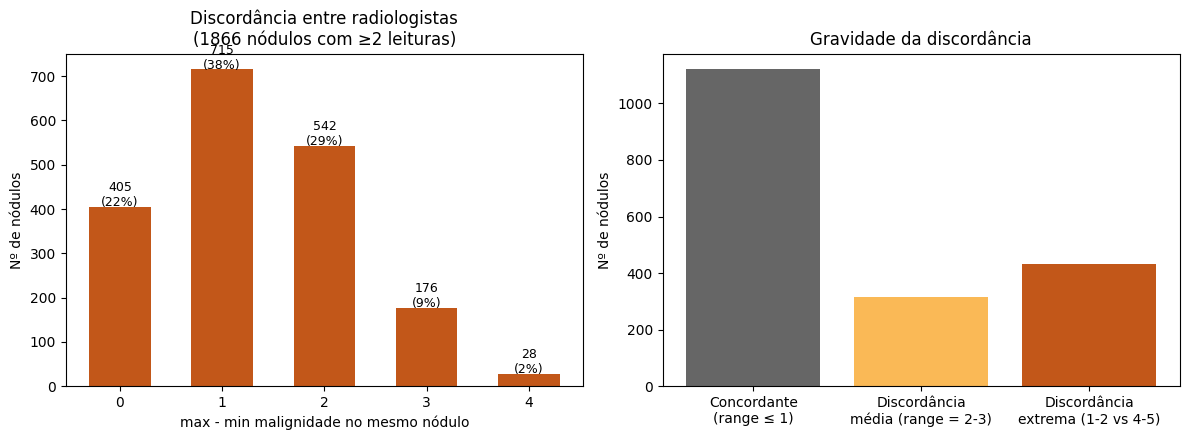

n = 1866 nódulos com ≥2 leituras
Concordância perfeita (range = 0): 405 (22%)
Discordância séria (range ≥ 2): 746 (40%)
Discordância extrema (1-2 vs 4-5): 431 (23%)


In [8]:
# Para cada nódulo (cluster), calcular a dispersão de malignidade entre radiologistas
dispersoes = []
for scan in scans_com_contornos:
    clusters = cluster_annotations_silent(scan)
    for cluster in clusters:
        if len(cluster) > 4:  # ignora clusters bugados
            continue
        ratings = [a.malignancy for a in cluster if a.malignancy is not None]
        if len(ratings) >= 2:
            dispersoes.append({
                'n_raters': len(ratings),
                'min': min(ratings),
                'max': max(ratings),
                'range': max(ratings) - min(ratings),
            })

df_disp = pd.DataFrame(dispersoes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma do range
counts = df_disp['range'].value_counts().reindex(range(5), fill_value=0)
axes[0].bar(counts.index, counts.values, width=0.6, color='#c25719')
for x, n in zip(counts.index, counts.values):
    axes[0].text(x, n + 2, f"{n}\n({100*n/len(df_disp):.0f}%)",
                 ha='center', fontsize=9)
axes[0].set_xlabel("max - min malignidade no mesmo nódulo")
axes[0].set_ylabel("Nº de nódulos")
axes[0].set_title(f"Discordância entre radiologistas\n({len(df_disp)} nódulos com ≥2 leituras)")

# Discordância extrema: 1-2 vs 4-5
extremo = ((df_disp['min'] <= 2) & (df_disp['max'] >= 4)).sum()
axes[1].bar(['Concordante\n(range ≤ 1)', 'Discordância\nmédia (range = 2-3)',
             'Discordância\nextrema (1-2 vs 4-5)'],
            [(df_disp['range'] <= 1).sum(),
             ((df_disp['range'] >= 2) & ~((df_disp['min'] <= 2) & (df_disp['max'] >= 4))).sum(),
             extremo],
            color=['#666666', '#fab956', '#c25719'])
axes[1].set_ylabel("Nº de nódulos")
axes[1].set_title("Gravidade da discordância")
plt.tight_layout()
plt.show()

print(f"n = {len(df_disp)} nódulos com ≥2 leituras")
print(f"Concordância perfeita (range = 0): {(df_disp['range'] == 0).sum()} ({(df_disp['range'] == 0).mean():.0%})")
print(f"Discordância séria (range ≥ 2): {(df_disp['range'] >= 2).sum()} ({(df_disp['range'] >= 2).mean():.0%})")
print(f"Discordância extrema (1-2 vs 4-5): {extremo} ({extremo/len(df_disp):.0%})")

**Conclusão:** dos 1866 nódulos do LIDC com duas ou mais leituras, apenas 405 (22%) têm concordância perfeita entre radiologistas. Outros 715 (38%) diferem por um único ponto, o que numa escala ordinal de 5 valores está próximo do ruído. Os restantes 746 (40%) diferem por dois pontos ou mais — discordância substancial.

O número mais relevante é o da discordância extrema: 431 nódulos (23%) foram classificados como benignos (1–2) por um radiologista e como malignos (4–5) por outro.

**Implicações para o pipeline:** a magnitude da discordância justifica três decisões. Primeiro, agregar por nódulo em vez de escolher uma leitura arbitrária — caso contrário, o rótulo dependeria do acaso de qual radiologista foi registado primeiro. Segundo, usar a média, que absorve a dispersão em vez de a amplificar como o máximo faria. Terceiro, manter uma classe intermédia (indeterminado) na classificação final, porque a discordância entre radiologistas não afeta apenas a confiança do rótulo — afeta a própria definição de "benigno" e "maligno" para os casos limítrofes.

### Estruturar melhor isto 

## Processar Anotações

Extrair coordenadas e características de cada anotação para análise.

**Nota sobre o `radiologo_id`:** no LIDC, a identidade dos radiologistas não é rastreável entre scans. O que podemos fazer é numerar as anotações dentro de um cluster (1 a 4). Isto **não é equivalente** ao `RadID` do LNDb, que identifica consistentemente o mesmo radiologista em todos os scans.

In [9]:
def extrair_nodulos_lidc(scan, max_nodulos=None):
    """NOTA: clusters com mais de 4 anotações sinalizamos com
    `cluster_suspeito=True` para poderem ser filtrados depois."""
    registos = []
    clusters = scan.cluster_annotations()

    for nodulo_idx, cluster in enumerate(clusters):
        if max_nodulos and nodulo_idx >= max_nodulos:
            break

        suspeito = len(cluster) > 4  # detetar cluster com mais de 4 anotações (bug do pylidc)

        for radiologista_idx, ann in enumerate(cluster):
            x, y, z = ann.centroid
            registos.append({
                'dataset':            'LIDC-IDRI',
                'scan_id':            scan.patient_id,
                'nodulo_id':          nodulo_idx,
                'x':                  float(x),
                'y':                  float(y),
                'z':                  float(z),
                'diametro_mm':        float(ann.diameter) if ann.diameter is not None else np.nan,
                'categoria':          1,
                'malignidade_rating': ann.malignancy,
                'radiologo_id':       radiologista_idx + 1,
                'cluster_suspeito':   suspeito,
            })
    return registos


todos = []
for pid in ['LIDC-IDRI-0001', 'LIDC-IDRI-0002', 'LIDC-IDRI-0003',
            'LIDC-IDRI-0004', 'LIDC-IDRI-0005']:
    s = pl.query(pl.Scan).filter(pl.Scan.patient_id == pid).first()
    if s is None:
        continue
    todos.extend(extrair_nodulos_lidc(s))

df_amostra = pd.DataFrame(todos)

# se decidirmos remover os clusters suspeitos (com mais de 4 anotações), descomentar a linha abaixo
#df_amostra = df_amostra[~df_amostra['cluster_suspeito']] 


"QUAL DESTAS FORMAS ESTÁ CORRETA????"
print(f"Amostra limpa: {len(df_amostra)} anotações "
      f"({df_amostra['nodulo_id'].nunique()} nódulos únicos em "
      f"{df_amostra['scan_id'].nunique()} scans)")

n_nodulos = df_amostra.groupby(['scan_id', 'nodulo_id']).ngroups
print(f"Amostra: {len(df_amostra)} anotações ({n_nodulos} nódulos únicos em "
      f"{df_amostra['scan_id'].nunique()} scans)")

# Ver distribuição de anotações por nódulo- confirmação de que a lógica está certa
print("\nAnotações por nódulo:")
print(df_amostra.groupby(['scan_id', 'nodulo_id']).size().reset_index(name='n_anotacoes'))

df_amostra.head(10)

Amostra limpa: 32 anotações (4 nódulos únicos em 5 scans)
Amostra: 32 anotações (10 nódulos únicos em 5 scans)

Anotações por nódulo:
          scan_id  nodulo_id  n_anotacoes
0  LIDC-IDRI-0001          0            4
1  LIDC-IDRI-0002          0            2
2  LIDC-IDRI-0003          0            1
3  LIDC-IDRI-0003          1            4
4  LIDC-IDRI-0003          2            4
5  LIDC-IDRI-0003          3            4
6  LIDC-IDRI-0004          0            4
7  LIDC-IDRI-0005          0            4
8  LIDC-IDRI-0005          1            4
9  LIDC-IDRI-0005          2            1


,dataset,scan_id,nodulo_id,x,y,z,diametro_mm,categoria,malignidade_rating,radiologo_id,cluster_suspeito
0,LIDC-IDRI,LIDC-IDRI-0001,0,365.874473,315.048523,89.551688,32.205888,1,5,1,False
1,LIDC-IDRI,LIDC-IDRI-0001,0,367.850606,316.277254,89.728129,33.188692,1,5,2,False
2,LIDC-IDRI,LIDC-IDRI-0001,0,366.955527,316.133418,89.538755,31.959332,1,5,3,False
3,LIDC-IDRI,LIDC-IDRI-0001,0,366.502720,316.467900,89.801959,33.669337,1,4,4,False
4,LIDC-IDRI,LIDC-IDRI-0002,0,363.265779,345.634122,184.442801,30.023172,1,5,1,False
5,LIDC-IDRI,LIDC-IDRI-0002,0,359.058796,344.810442,185.646284,31.540171,1,4,2,False
6,LIDC-IDRI,LIDC-IDRI-0003,0,346.394690,368.923894,66.148673,31.664468,1,2,1,False
7,LIDC-IDRI,LIDC-IDRI-0003,1,349.583636,366.900000,75.232727,30.351544,1,5,1,False
8,LIDC-IDRI,LIDC-IDRI-0003,1,350.834008,367.080972,75.275304,30.117853,1,5,2,False
9,LIDC-IDRI,LIDC-IDRI-0003,1,350.614341,367.385659,75.242248,27.998968,1,3,3,False


Extrai a lista de nódulos de um scan LIDC-IDRI no esquema combinado.
Cada linha corresponde a UMA anotação (um radiologista).

## Visualizar um Nódulo

Confirmamos visualmente que os centroides e as máscaras correspondem a nódulos reais.

Loading dicom files ... This may take a moment.


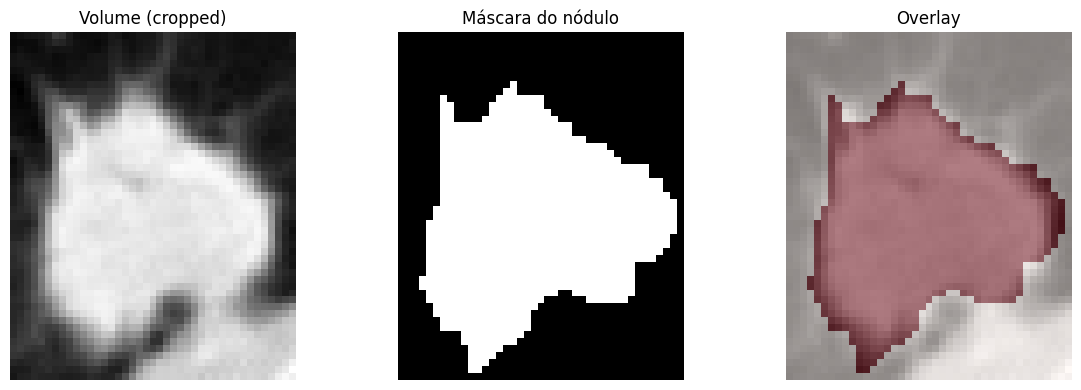

Diâmetro: 32.21 mm
Malignidade: 5
Textura: 5


In [10]:
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == 'LIDC-IDRI-0001').first()
clusters = scan.cluster_annotations()

if len(clusters) > 0:
    cluster = clusters[0]
    ann = cluster[0]  # primeira anotação do primeiro nódulo

    # Bounding box e máscara
    bbox = ann.bbox()
    volume = scan.to_volume()
    cropped = volume[bbox]
    mask = ann.boolean_mask()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    slice_idx = cropped.shape[2] // 2

    axes[0].imshow(cropped[:, :, slice_idx], cmap='gray')
    axes[0].set_title('Volume (cropped)')
    axes[0].axis('off')

    axes[1].imshow(mask[:, :, slice_idx], cmap='gray')
    axes[1].set_title('Máscara do nódulo')
    axes[1].axis('off')

    axes[2].imshow(cropped[:, :, slice_idx], cmap='gray')
    axes[2].imshow(mask[:, :, slice_idx], cmap='Reds', alpha=0.5)
    axes[2].set_title('Overlay')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"Diâmetro: {ann.diameter:.2f} mm")
    print(f"Malignidade: {ann.malignancy}")
    print(f"Textura: {ann.texture}")

## EDA- Distribuição de diâmetro dos nódulos

O diâmetro é a variável mais diretamente ligada à decisão de tamanho de patch. No LIDC o diâmetro é calculado pelo pylidc a partir do contorno (`ann.diameter`), ao contrário do LNDb onde vem de um volume segmentado.

**O que esta distribuição decide:** o tamanho da patch de treino. Se a patch for demasiado pequena, corta os nódulos maiores; se for demasiado grande, o nódulo ocupa uma fração minúscula da imagem e o modelo perde capacidade de foco.

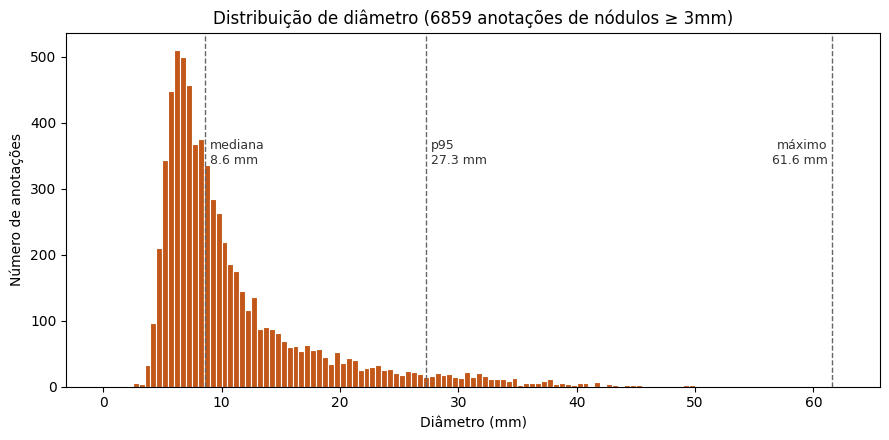

n = 6859
mediana = 8.65 mm
p95 = 27.29 mm
máx = 61.58 mm
min = 2.54 mm


In [11]:
# Recolher todos os diâmetros de nódulos >= 3mm (com malignidade) 
"""onde é que eu especifico que tem que te tamanho superior a 3mm?"""
diametros = []
for scan in scans_com_contornos:
    for ann in scan.annotations:
        if ann.malignancy is not None and ann.diameter is not None:
            diametros.append(ann.diameter)

diametros = np.array(diametros)
p50, p95, dmax = np.percentile(diametros, [50, 95, 100])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(diametros, bins=np.arange(0, diametros.max() + 1, 0.5),
        color='#c25719', edgecolor='white', linewidth=0.8)
top = ax.get_ylim()[1]
for val, name, align in [(p50, "mediana", "left"),
                          (p95, "p95", "left"),
                          (dmax, "máximo", "right")]:
    ax.axvline(val, color='#666666', linestyle='--', linewidth=1)
    offset = 0.4 if align == "left" else -0.4
    ax.text(val + offset, top*0.7, f"{name}\n{val:.1f} mm",
            ha=align, va='top', fontsize=9, color='#333333')
ax.set_xlabel("Diâmetro (mm)")
ax.set_ylabel("Número de anotações")
ax.set_title(f"Distribuição de diâmetro ({len(diametros)} anotações de nódulos ≥ 3mm)")
plt.tight_layout()
plt.show()

print(f"n = {len(diametros)}")
print(f"mediana = {p50:.2f} mm")
print(f"p95 = {p95:.2f} mm")
print(f"máx = {dmax:.2f} mm")
print(f"min = {diametros.min():.2f} mm")

**Conclusion:** the 6859 annotations have a median diameter of 8.65 mm, a 95th percentile of 27.29 mm and a maximum of 61.58 mm. The distribution is strongly skewed to the right: most nodules are small, with a long tail of large ones. The minimum is 2.54 mm, the 5 cases under 3 mm discussed above, which come from the difference between the in plane criterion of the LIDC protocol (Armato et al., 2011) and the equivalent diameter computed by pylidc.

Two consequences for the pipeline:

**Size of the patch.** These diameters are per annotation, and the largest is the outline of a single reader. What has to fit in the patch is the region the models use, the consensus of the readers. Notebook 05 measures it: a 64 mm cube cuts no consensus region, while a 30 mm cube would cut 106 LIDC IDRI regions and a 51 mm cube 3. We therefore use the same 64 mm cube in both datasets.

**Resampling is needed.** The diameter is in millimetres but the in plane spacing changes between scans (typically 0.5 to 0.8 mm), so comparing nodules from different scans requires resampling to an isotropic spacing.

## EDA- Voxel spacing entre scans

O LIDC foi adquirido em 7 instituições com scanners diferentes, ao contrário do LNDb (1 instituição, 3 modelos Siemens). A heterogeneidade de spacing é o principal motivo pelo qual faz sentido resampling antes da extração de features.

**O que isto decide:** se vale a pena resamplear para spacing isotrópico, e para que valor. A resposta para o LNDb já foi "sim". Aqui queremos ver se o LIDC permite o mesmo alvo.

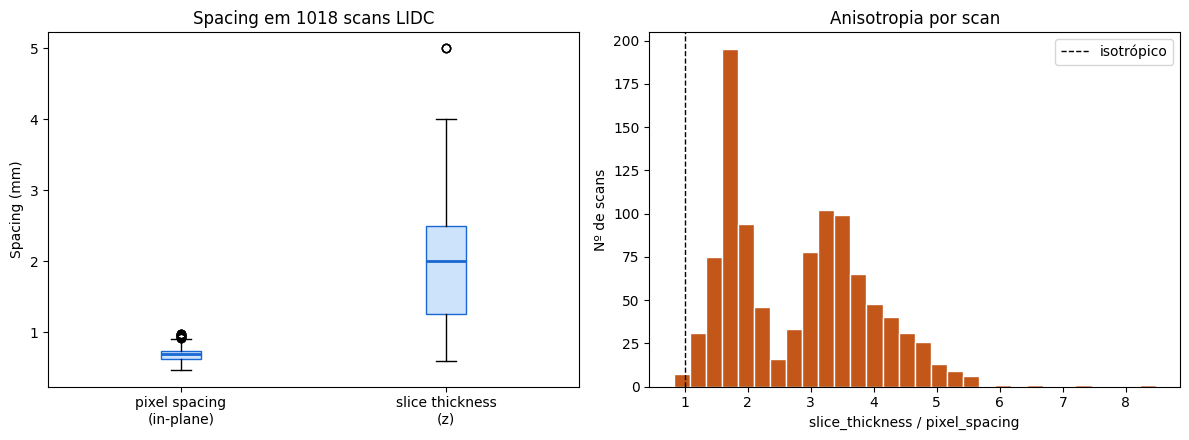

       pixel_spacing  slice_thickness  anisotropy
count       1018.000         1018.000    1018.000
mean           0.688            1.919       2.821
std            0.085            0.729       1.122
min            0.461            0.600       0.821
25%            0.625            1.250       1.778
50%            0.699            2.000       2.917
75%            0.742            2.500       3.556
max            0.977            5.000       8.477

Scans isotrópicos (ratio entre 0.95 e 1.05): 2


In [12]:
# Recolher spacing de todos os scans
spacings = []
for scan in pl.query(pl.Scan):
    spacings.append({
        'patient_id': scan.patient_id,
        'slice_thickness': scan.slice_thickness,
        'pixel_spacing': scan.pixel_spacing,
    })
df_spacing = pd.DataFrame(spacings)

# Anisotropia z/x
df_spacing['anisotropy'] = df_spacing['slice_thickness'] / df_spacing['pixel_spacing']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Boxplot
axes[0].boxplot([df_spacing['pixel_spacing'].dropna(),
                 df_spacing['slice_thickness'].dropna()],
                tick_labels=['pixel spacing\n(in-plane)', 'slice thickness\n(z)'],
                patch_artist=True,
                boxprops=dict(facecolor='#cde2fb', edgecolor='#1967d2'),
                medianprops=dict(color='#1967d2', linewidth=2))
axes[0].set_ylabel("Spacing (mm)")
axes[0].set_title(f"Spacing em {len(df_spacing)} scans LIDC")

# Histograma de anisotropia
axes[1].hist(df_spacing['anisotropy'].dropna(), bins=30,
             color='#c25719', edgecolor='white')
axes[1].axvline(1.0, color='black', linestyle='--', linewidth=1, label='isotrópico')
axes[1].set_xlabel("slice_thickness / pixel_spacing")
axes[1].set_ylabel("Nº de scans")
axes[1].set_title("Anisotropia por scan")
axes[1].legend()
plt.tight_layout()
plt.show()

print(df_spacing[['pixel_spacing', 'slice_thickness', 'anisotropy']].describe().round(3))
print(f"\nScans isotrópicos (ratio entre 0.95 e 1.05): "
      f"{((df_spacing['anisotropy'] > 0.95) & (df_spacing['anisotropy'] < 1.05)).sum()}")

**Conclusion:** the 1018 LIDC scans have a median in plane spacing of 0.70 mm (interquartile range 0.63 to 0.74 mm) and a median slice thickness of 2.00 mm (interquartile range 1.25 to 2.50 mm), with values up to 5.00 mm. The ratio between slice thickness and pixel spacing has a median of 2.92, and only 2 of the 1018 scans are isotropic. In almost every scan a voxel is about three times taller than it is wide.

**Implications for the pipeline:**

**Resampling is needed.** 3D texture features (GLCM, GLRLM and similar) compare neighbouring voxels as if they were at the same physical distance in every direction. In an anisotropic volume that is false, and the features mix different scales. The Image Biomarker Standardisation Initiative asks for resampling to a common isotropic spacing before extracting features, so that scans are comparable and 3D features are rotationally invariant (Zwanenburg et al., 2016). It does not prescribe the size of the voxel.

**We use 1 mm.** A voxel close to the in plane spacing (about 0.7 mm) would keep the in plane detail, but along z it would only interpolate: the median LIDC slice is 2 mm, so a 0.7 mm grid would place about three grid slices on every real one. LNDb, the other dataset of the model, has 1 mm slices in 289 of its 294 scans, so 1 mm is the real resolution of its coarsest axis and gives the same physical voxel in both datasets. The price is a light loss of in plane resolution. Notebook 05 tests this choice with a sensitivity analysis at 0.6, 1, 1.5 and 2 mm, on coverage, robustness between readers, dependence on the acquisition and prediction.

**A note on the limits of resampling.** Recent studies show that isotropic resampling alone does not remove the effect of slice thickness on radiomic features (Yang et al., 2021; Peoples et al., 2025). One alternative extracts features directly from the native images, taking the physical voxel size into account without interpolation (Corral Fontecha et al., 2026). It keeps the original signal but is outside the scope of this work; resampling remains the established standard and allows direct comparison with the literature.

## Distribuição de malignidade por nódulo único

O histograma da secção anterior conta cada anotação individualmente: um nódulo lido por 4 radiologistas contribui 4 vezes, mesmo sendo um só nódulo. Isto sobre-conta as classes, sobretudo as que os radiologistas marcaram com mais frequência.

Nesta secção agregamos por nódulo único, usando a média das leituras entre radiologistas. Esta é a distribuição que corresponde aos rótulos reais de treino: quando chegarmos ao classificador, cada nódulo é um exemplo, não cada anotação.

Os limiares 2.5 e 3.5 definem as três classes usadas na classificação final: benigno (≤ 2.5), indeterminado (2.5–3.5) e maligno (> 3.5).

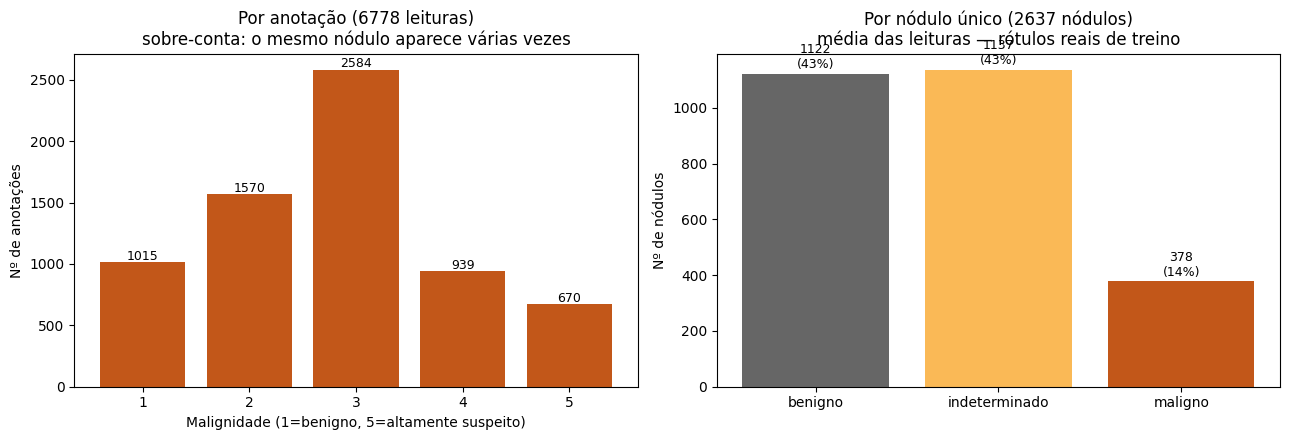

Nódulos únicos: 2637
Benignos (≤ 2.5):          1122 (43%)
Indeterminados (2.5-3.5):  1137 (43%)
Malignos (> 3.5):           378 (14%)


In [13]:
# --- Contagens por anotação (sobre-conta) ---
malignidades_anot = []
for scan in scans_com_contornos:
    for cluster in cluster_annotations_silent(scan):
        if len(cluster) > 4:
            continue
        for ann in cluster:
            if ann.malignancy is not None:
                malignidades_anot.append(ann.malignancy)

dist_anot = pd.Series(malignidades_anot).value_counts().reindex([1, 2, 3, 4, 5]).fillna(0)

# --- Contagens por nódulo único (agregado) ---
malignidade_por_nodulo = []
for scan in scans_com_contornos:
    for cluster in cluster_annotations_silent(scan):
        if len(cluster) > 4:
            continue
        ratings = [a.malignancy for a in cluster if a.malignancy is not None]
        if len(ratings) > 0:
            malignidade_por_nodulo.append(np.mean(ratings))
malignidade_por_nodulo = np.array(malignidade_por_nodulo)

def classificar(m):
    if m <= 2.5: return 'benigno'
    elif m <= 3.5: return 'indeterminado'
    else: return 'maligno'

contagem_nodulo = pd.Series([classificar(m) for m in malignidade_por_nodulo]).value_counts()
contagem_nodulo = contagem_nodulo.reindex(['benigno', 'indeterminado', 'maligno'])

# --- Plot lado a lado ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Esquerda: por anotação (sobre-conta)
bars0 = axes[0].bar(dist_anot.index, dist_anot.values, color='#c25719')
for bar, n in zip(bars0, dist_anot.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, n + 20,
                 f"{int(n)}", ha='center', fontsize=9)
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_xlabel("Malignidade (1=benigno, 5=altamente suspeito)")
axes[0].set_ylabel("Nº de anotações")
axes[0].set_title(f"Por anotação ({sum(dist_anot.values):.0f} leituras)\n"
                  f"sobre-conta: o mesmo nódulo aparece várias vezes")

# Direita: por nódulo único (o que interessa)
cores = ['#666666', '#fab956', '#c25719']
bars1 = axes[1].bar(contagem_nodulo.index, contagem_nodulo.values, color=cores)
for bar, n in zip(bars1, contagem_nodulo.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, n + 20,
                 f"{n}\n({100*n/contagem_nodulo.sum():.0f}%)",
                 ha='center', fontsize=9)
axes[1].set_ylabel("Nº de nódulos")
axes[1].set_title(f"Por nódulo único ({len(malignidade_por_nodulo)} nódulos)\n"
                  f"média das leituras — rótulos reais de treino")

plt.tight_layout()
plt.show()

print(f"Nódulos únicos: {len(malignidade_por_nodulo)}")
print(f"Benignos (≤ 2.5):         {contagem_nodulo['benigno']:5d} ({100*contagem_nodulo['benigno']/contagem_nodulo.sum():.0f}%)")
print(f"Indeterminados (2.5-3.5): {contagem_nodulo['indeterminado']:5d} ({100*contagem_nodulo['indeterminado']/contagem_nodulo.sum():.0f}%)")
print(f"Malignos (> 3.5):         {contagem_nodulo['maligno']:5d} ({100*contagem_nodulo['maligno']/contagem_nodulo.sum():.0f}%)")

**Conclusão:** dos 2637 nódulos únicos do LIDC com malignidade avaliada, a distribuição ternária é bastante diferente do que o histograma por anotação sugeria. Após agregar as leituras por média, 1122 nódulos (43%) ficam classificados como benignos (média ≤ 2.5), 1137 (43%) como indeterminados (2.5–3.5) e apenas 378 (14%) como malignos (> 3.5).

**A observação central é a dimensão da classe indeterminada.** Quase metade dos nódulos cai na zona cinzenta, uma proporção muito superior à do LNDb, onde a classe intermédia era residual. A razão é dupla. Primeiro, o LIDC tem até 4 radiologistas por nódulo, contra 1–2 na maioria dos casos do LNDb; segundo, a agregação por média empurra para o meio qualquer nódulo onde os radiologistas divergem — duas leituras [2, 4] ou [1, 5] caem ambas em 3.0 e ficam indeterminadas. Uma fração substancial do indeterminado no LIDC não representa incerteza genuína dos radiologistas, representa dispersão entre eles.

**Implicações para o pipeline:**

**Descartar a classe indeterminada custaria quase metade do conjunto de treino.** Como discutido na secção de concordância (Lei et al., 2020; Zhang et al., 2022), esta classe não deve ser removida silenciosamente. Com 43% dos nódulos nesta zona, excluí-los reduziria o treino para ~1500 exemplos — menos de 60% do total — e enviesaria o modelo para os casos onde há consenso, que são precisamente os mais fáceis. A decisão de manter a classe ou de a usar em treino com uma função de perda ordinal tem de ser explícita.

**A prevalência de malignidade é maior no LIDC do que no LNDb.** Aqui, 14% dos nódulos classificam-se como malignos, contra 13% no LNDb (por leitura). A proporção é semelhante, mas a razão benigno:maligno é muito menor no LIDC — 3:1 aqui, contra 5:1 no LNDb — porque a classe indeterminada absorve a maioria dos casos que no LNDb seriam benignos. Isto significa que estratégias de class weights ou resampling pensadas para o LNDb podem não transferir diretamente.

## Parâmetros de aquisição

O LNDb é homogéneo (uma instituição, 3 modelos Siemens). O LIDC não: 7 instituições, vários fabricantes, vários protocolos. Isto afeta a distribuição de intensidades das imagens e, por consequência, as features extraídas.

**O que isto decide:** se é preciso normalização de intensidade mais agressiva, e se fabricante/modelo deve entrar como feature ou como variável de confundimento.

Scans com DICOM acessível:  1018
Scans sem DICOM local:      0
Total:                      1018


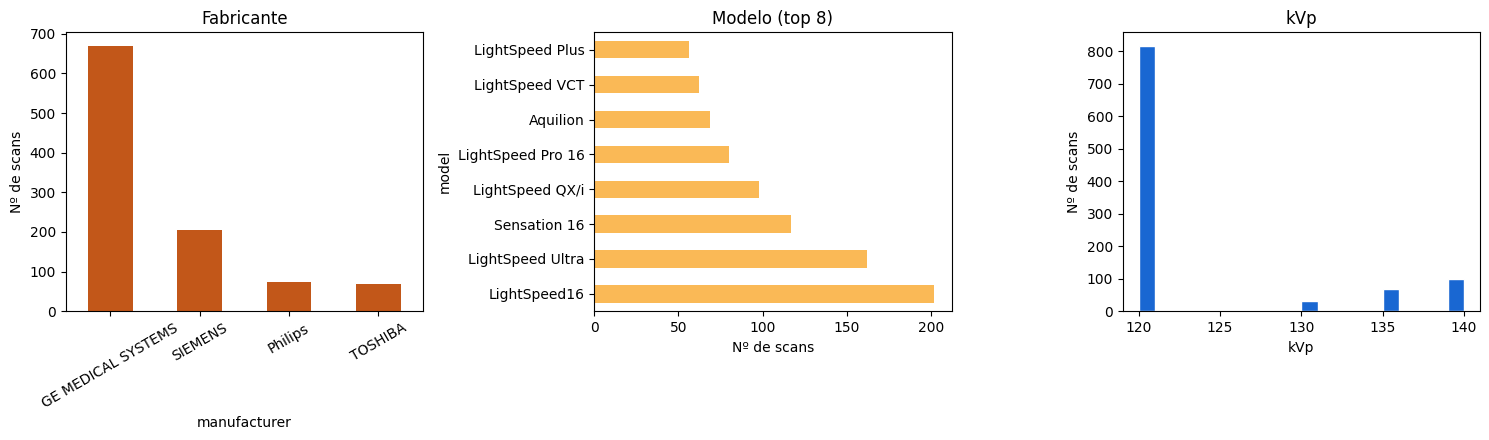


kVp: min=120, mediana=120, max=140


In [14]:
import pydicom
from pathlib import Path

TAGS_AQUISICAO = {
    'manufacturer':        'Manufacturer',
    'model':               'ManufacturerModelName',
    'kvp':                 'KVP',
    'exposure':            'Exposure',
    'convolution_kernel':  'ConvolutionKernel',
    'institution_name':    'InstitutionName',
}

def extrair_metadados_dicom(scan):
    """Lê o primeiro DICOM do scan. Devolve None se a pasta não existir ou estiver vazia."""
    try:
        dicom_dir = Path(scan.get_path_to_dicom_files())
    except Exception:
        return None
    dcm_files = sorted(f for f in dicom_dir.glob('*.dcm') if not f.name.startswith('._'))  # ignora as cópias '._' do macOS, que não são DICOM
    if not dcm_files:
        return None

    ds = pydicom.dcmread(str(dcm_files[0]), stop_before_pixels=True)
    resultado = {'patient_id': scan.patient_id}
    for nome_coluna, tag in TAGS_AQUISICAO.items():
        valor = getattr(ds, tag, None)
        if isinstance(valor, (list, tuple)):
            valor = str(valor[0]) if len(valor) > 0 else None
        resultado[nome_coluna] = valor
    return resultado

# Recolher, ignorando silenciosamente os scans sem DICOM
aquisicao = []
n_sem_dicom = 0
for scan in pl.query(pl.Scan):
    meta = extrair_metadados_dicom(scan)
    if meta is None:
        n_sem_dicom += 1
        continue
    aquisicao.append(meta)

df_aq = pd.DataFrame(aquisicao)
print(f"Scans com DICOM acessível:  {len(df_aq)}")
print(f"Scans sem DICOM local:      {n_sem_dicom}")
print(f"Total:                      {len(df_aq) + n_sem_dicom}")

# --- Gráficos ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

df_aq['manufacturer'].dropna().value_counts().plot(kind='bar', ax=axes[0], color='#c25719')
axes[0].set_title("Fabricante")
axes[0].set_ylabel("Nº de scans")
axes[0].tick_params(axis='x', rotation=30)

df_aq['model'].dropna().value_counts().head(8).plot(kind='barh', ax=axes[1], color='#fab956')
axes[1].set_title("Modelo (top 8)")
axes[1].set_xlabel("Nº de scans")

kvp_vals = pd.to_numeric(df_aq['kvp'], errors='coerce').dropna()
axes[2].hist(kvp_vals, bins=20, color='#1967d2', edgecolor='white')
axes[2].set_title("kVp")
axes[2].set_xlabel("kVp")
axes[2].set_ylabel("Nº de scans")

plt.tight_layout()
plt.show()

print(f"\nkVp: min={kvp_vals.min():.0f}, mediana={kvp_vals.median():.0f}, max={kvp_vals.max():.0f}")

vou esperar pelos resultados :)

## Decisão- Consensus de máscaras

Como discutido na secção 5, o LNDb tem uma máscara 3D por nódulo por radiologista, pré-computada. O LIDC não tem máscaras em ficheiro: tem contornos XML que o pylidc reconstrói em memória. Quando um nódulo tem mais do que um radiologista, temos de **decidir como produzir uma única máscara por nódulo**, porque o classificador não pode treinar em 4 máscaras diferentes para o mesmo nódulo.

Três opções possíveis:

| Método | Regra | Vantagem | Desvantagem |
|---|---|---|---|
| **Union** | voxel positivo se ≥1 radiologista o marcou | preserva todo o nódulo | sobre-estima o volume, inclui tecido normal |
| **Interseção** | voxel positivo se todos marcaram | conservador | máscara pode ficar vazia |
| **Voto por maioria** | voxel positivo se > 50% marcaram | equilíbrio, default da literatura | precisa de ≥2 radiologistas |

**Decisão tomada:** voto por maioria (`pylidc.utils.consensus()`), porque é o default da literatura e é o que melhor reflete "a opinião da maioria" quando há discordância. Nódulos com um só radiologista ficam com a máscara desse radiologista (não há consensus a fazer).

Loading dicom files ... This may take a moment.


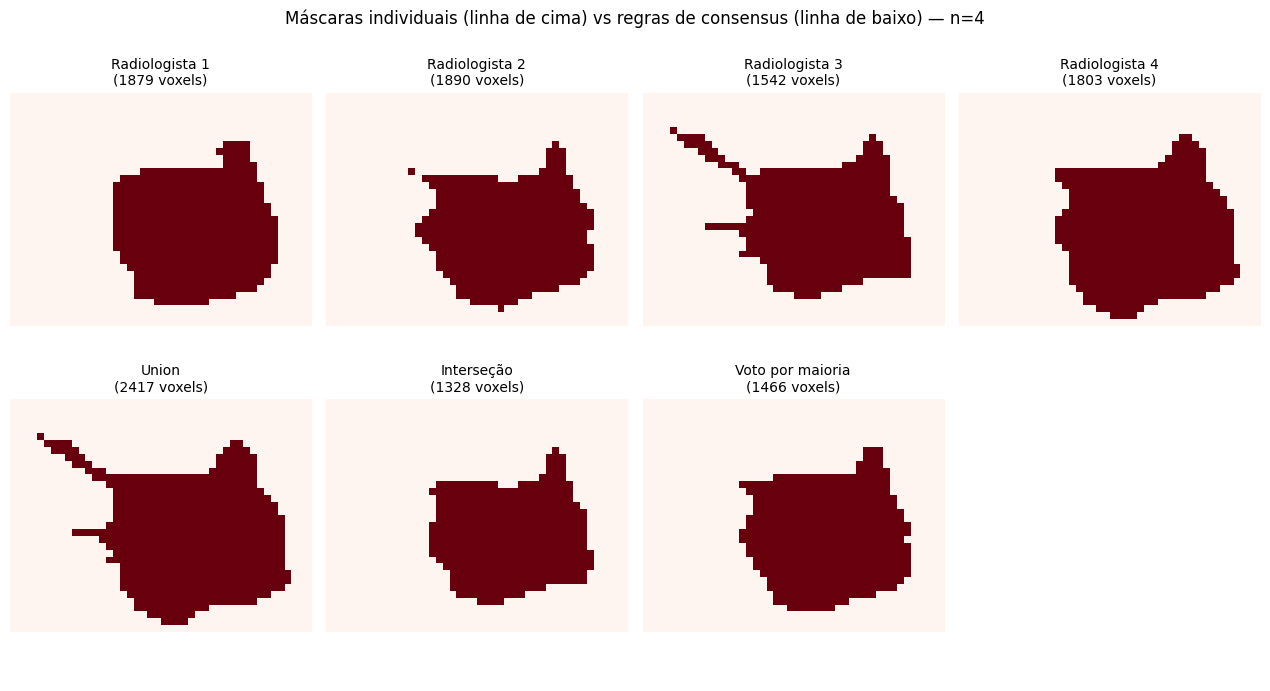

In [15]:
# Comparar as máscaras individuais e as três regras de consensus no mesmo nódulo.

# 1. Escolher o primeiro cluster com 2 a 4 anotações
exemplo_scan = None
exemplo_cluster = None
for scan in pl.query(pl.Scan):
    for cluster in cluster_annotations_silent(scan):
        if 2 <= len(cluster) <= 4:
            exemplo_scan, exemplo_cluster = scan, cluster
            break
    if exemplo_scan is not None:
        break

if exemplo_scan is None:
    print("Não foi encontrado nenhum nódulo com 2-4 anotações.")
else:
    # 2. Colocar cada máscara no sistema de coordenadas global do volume
    volume = exemplo_scan.to_volume()
    masks_globais = []
    for ann in exemplo_cluster:
        mask_global = np.zeros(volume.shape, dtype=bool)
        mask_global[ann.bbox()] = ann.boolean_mask()
        masks_globais.append(mask_global)

    # 3. Bounding box comum
    bboxes = [ann.bbox() for ann in exemplo_cluster]
    bbox_comum = tuple(
        slice(min(b[i].start for b in bboxes),
              max(b[i].stop  for b in bboxes))
        for i in range(3)
    )

    # 4. Três regras de consensus
    stack = np.stack(masks_globais, axis=0).astype(np.uint8)
    n = len(exemplo_cluster)

    mask_union    = stack.any(axis=0)
    mask_inter    = stack.all(axis=0)
    mask_majority = stack.sum(axis=0) > (n / 2)

    # 5. Recortar pela bbox comum
    masks_c         = [m[bbox_comum] for m in masks_globais]
    mask_union_c    = mask_union[bbox_comum]
    mask_inter_c    = mask_inter[bbox_comum]
    mask_majority_c = mask_majority[bbox_comum]

    fatia = mask_union_c.shape[2] // 2

    # 6. Gráfico em duas linhas
    n_cols = max(n, 3)
    fig, axes = plt.subplots(2, n_cols, figsize=(3.2 * n_cols, 7))

    # Linha 1: máscaras individuais
    for i, mask in enumerate(masks_c):
        ax = axes[0, i]
        ax.imshow(mask[:, :, fatia], cmap='Reds')
        ax.set_title(f"Radiologista {i+1}\n({mask.sum()} voxels)", fontsize=10)
        ax.axis('off')
    for j in range(n, n_cols):
        axes[0, j].axis('off')

    # Linha 2: regras de consensus
    regras = [
        (mask_union_c,    "Union"),
        (mask_inter_c,    "Interseção"),
        (mask_majority_c, "Voto por maioria"),
    ]
    for j, (mask, nome) in enumerate(regras):
        ax = axes[1, j]
        ax.imshow(mask[:, :, fatia], cmap='Reds')
        ax.set_title(f"{nome}\n({mask.sum()} voxels)", fontsize=10)
        ax.axis('off')
    for j in range(3, n_cols):
        axes[1, j].axis('off')

    plt.suptitle(f"Máscaras individuais (linha de cima) vs regras de consensus (linha de baixo) — n={n}",
                 fontsize=12)
    plt.tight_layout()
    plt.show()

**Conclusão:** as máscaras individuais (linha de cima) mostram que os quatro radiologistas discordam nos contornos mesmo para o mesmo nódulo físico — cada um desenha uma forma diferente em extensão e forma. As contagens confirmam-no: os radiologistas individuais produzem 1542–1890 voxels, a união 2417, a interseção 1328 e o voto por maioria 1466. A escolha da regra de consensus tem, por isso, impacto direto no volume final da máscara, e consequentemente em qualquer feature radiomica derivada do seu interior.

**A decisão sobre o threshold é a parte crítica.** O default da literatura é o **voto por maioria (≥50%)**, que é também o default do `pylidc` — a função `consensus` com `clevel=0.5` marca um voxel como positivo quando mais de metade dos radiologistas o marcaram (Carrazza et al., 2016; LA-ResUNet, 2024; AutoRad-Lung, 2025). Esta é a regra adotada neste projeto: com 4 radiologistas, um voxel é positivo se ≥3 concordarem, e com 2 ou 3 radiologistas o critério ajusta-se proporcionalmente.

**A alternativa é a união**, que maximiza recall ao incluir qualquer voxel marcado por pelo menos um radiologista. O estudo fundamental de Ross et al. (2007) comparou explicitamente união, interseção e STAPLE em 41 exames do LIDC e concluiu que *"using the union as the consensus scheme produced the greatest number of nodule-positive voxels while using the intersection produced the fewest"*. Isto significa que a união é a escolha correta quando o objetivo é maximizar sensibilidade — por exemplo, em tarefas de deteção onde perder um nódulo é mais grave do que incluir tecido adjacente. A interseção, por oposição, é a mais conservadora e pode produzir máscaras fragmentadas ou vazias quando os contornos discordam muito.

Para classificação de malignidade, o voto por maioria é o compromisso correto: não inflaciona o volume como a união (que inclui tecido perinodular marcado por um só radiologista) nem o reduz excessivamente como a interseção (que pode eliminar regiões de consenso parcial). A maioria fica próxima do radiologista médio em tamanho, o que é desejável para manter a comparabilidade com as features extraídas de anotações individuais.

**Nota:** para nódulos com apenas 1 anotação — que são ~29% do dataset, como visto na secção de cobertura — não há consensus a aplicar. A máscara é a do único radiologista, usada tal como está.

## Análise de Malignidade

## Diferenças relevantes LIDC-IDRI vs. LNDb

### Diferenças estruturais

| Aspeto | LIDC-IDRI | LNDb |
|---|---|---|
| **Nº de scans** | 1018 séries de TC | 294 séries |
| **Nº de instituições** | 7 | 1 (CHUSJ, Porto) |
| **Metodologia** | 4 radiólogos, 2 fases (blinded + unblinded) | 5 radiólogos, single-blind |
| **Identidade dos radiologistas** | Anónima, não rastreável entre scans | Rastreável (R1-R5 consistentes) |
| **Formato das imagens** | DICOM (.dcm) por fatia | MetaImage (.mhd/.raw) |
| **Formato das anotações** | XML (`LidcReadMessage`) com contornos por fatia | CSV com coordenadas 3D do centro + volume |
| **Segmentação** | Contornos 2D por fatia (é preciso reconstruir) | Máscara 3D pré-computada |
| **Volume do nódulo** | Calculado a partir do contorno | Fornecido diretamente (em mm³) |
| **Diâmetro** | Calculado (`annotation.diameter`) | Calculado por `nodEqDiam` a partir do volume |
| **Características subjetivas** | 9 (subtlety, internalStructure, calcification, sphericity, margin, lobulation, spiculation, texture, malignancy) | 7 (calcification, internalStructure, lobulation, malignancy, margin, sphericity, spiculation, subtlety) |
| **Conjunto de treino** | Não há split oficial | Split oficial `train`/`test` |
| **Aquisição** | Muito heterogénea (7 instituições, vários scanners) | Homogénea (1 instituição) |

### Implicações para o pipeline


1. Distribuição de labels por radiologista, não por nódulo.</strong> Se um nódulo tem 4 anotações e 3 radiólogos lhe deram malignidade = 2 e 1 deu = 3, a linha "oficial" não existe — temos de decidir como agregar (média, mediana, maioria, ou manter as 4 linhas separadas como no LNDb).

2. **A máscara é 3D mas esparsa.** No LNDb a máscara é um volume binário denso. No LIDC, `ann.boolean_mask()` devolve uma máscara no bounding box — o pipeline tem de lidar com ambas.

3. **Contornos têm de ser fundidos.** Se quisermos uma máscara "de consenso" (como no LNDb, em que há uma máscara por nódulo), temos de aplicar `pl.utils.consensus()` ou uma regra de maioria.

4. **Não há `RadID` estável.** Não vai ser possível usar o radiologista como feature.

5. **Escalas diferentes.** No LNDb, os valores de `malignancy` vêm diretamente do CSV. No LIDC, `pylidc` normaliza.

6. Ficheiros XML duplicados.</strong> O pacote oficial contém, para cada série de TC, um XML de TC (<code>LidcReadMessage</code>) e frequentemente um XML de radiografia de tórax (<code>IdriReadMessage</code>). O <code>pylidc</code> <strong>só processa os XMLs de TC</strong>.


### Atenção

Para aceder ao volume é preciso ter as imagens DICOM em disco e configurar o `pylidcrc` com o caminho correto. No LNDb, o `utils.py` lê diretamente o `.mhd`. Além disso, ao contrário do LNDb (que fornece volumes pré-computados em MetaImage), o LIDC-IDRI guarda os contornos como sequências de pontos <code>(x, y, z)</code> por fatia. O volume tem de ser reconstruído.

Cada radiologista marcou as lesões em três categorias: <em>nódulo ≥ 3 mm</em>, <em>nódulo &lt; 3 mm</em>, e <em>não-nódulo ≥ 3 mm</em>. Apenas nódulos ≥ 3 mm têm contornos 3D e as 9 características subjetivas.

## Bases ciencítificas 

- Armato, S. G., et al. (2011). The Lung Image Database Consortium (LIDC) and Image Database Resource Initiative (IDRI): A completed reference database of lung nodules on CT scans. Medical Physics, 38(2), 915–931. - https://staging.europepmc.org/article/MED/21452728#free-full-text#4-  define o critério de 3 mm do LIDC como o maior diâmetro in-plane e nota que o diâmetro reconstruído pode ser inferior, justificando os 5 casos abaixo do limiar.

- Yang, Y., et al. (2023). Attention-guided deep neural network with a multichannel architecture for lung nodule classification. Heliyon. — justifica a estratégia multiescala pela variação de tamanhos de nódulos no LIDC-IDRI.

- Ross, J. C., Miller, J. V., Turner, W. D., & Kelliher, T. P. (2007). *An analysis of early studies released by the Lung Imaging Database Consortium (LIDC)*. Academic Radiology, 14(11), 1382–1388. — compara esquemas de consensus (união, interseção, STAPLE) em 41 exames do LIDC e conclui que a união produz o maior número de voxels positivos e a interseção o menor.
- Carrazza, M., Kennedy, B., Rasin, A., Furst, J., & Raicu, D. (2016). *Investigating the effects of majority voting on CAD systems: A LIDC case study*. Medical Imaging 2016: Computer-Aided Diagnosis, SPIE. — investiga os efeitos do majority voting em sistemas CAD treinados no LIDC, mostrando que a escolha da regra de agregação afeta significativamente o desempenho.
- LA-ResUNet (2024). *An Efficient Linear Attention Mechanism in ResUNet for the Semantic Segmentation of Pulmonary Nodules*. IEEE. — usa a função `consensus` do `pylidc` com 50% de consenso entre radiologistas para gerar a máscara de ground truth.
- AutoRad-Lung (2025). arXiv:2503.20662. — define o boundary do nódulo "only if at least 50% of the annotators agree", usando consensus-based mask para extração de features radiomicas.

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
from src.mass_detect.scripts.config import NODULE_TABLE as OUTPUT
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.mass_detect.scripts.config import LIDC_NODULES_FILE, READER_RATINGS_FILE
from src.mass_detect.scripts.lidc import MAX_READERS, build_lidc_table, centre_spread, describe_annotation, import_pylidc, save_lidc_reader_ratings, split_oversized_group
from src.mass_detect.scripts.schema import SCHEMA

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LIDC groups with more than four annotations
  </h3>

  <p>
    Each LIDC IDRI scan was read by four radiologists, so one physical nodule should have at most four annotations. 'pylidc' decides which annotations belong to the same nodule by joining those whose contours are closer than a tolerance. When a group ends up with more than four annotations it shrinks the tolerance by 10% and tries again, until the tolerance drops below 0.1 mm. If that still fails it returns the oversized group.
  </p>
  <p>  
    Every value in a row is computed from its group. The label is the mean of the ratings, the centre is the mean of the centres and the size comes from the mean volume. If two different nodules fall in one group, the row describes something that does not exist. In the 14 affected groups (81 annotations in total):
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">the ratings alone tell us little, because about 18% of the ordinary nodules with four readers also have ratings that range by three points or more. The positions are better evidence;</li>
    <li style="margin-bottom: 8px;">in many of them the annotated centres are 13 to 38 mm apart, while the nodules have median diameters between 11 and 33 mm, so the mean centre can land on healthy tissue between two nodules and spoil every patch and radiomic feature computed later;</li>
    <li style="margin-bottom: 8px;">a few are compact and unanimous (for example five annotations that are all rated 5). Those may be a single nodule with an extra annotation. The data alone cannot tell us.</li>
  </ul>
  <p>  
    First, we considered to keep the groups and only flag them (our first version), but corrupted rows stay in the table unless every experiment remembers to filter them. Then, we also considered excluding them, but we would lose 0.5% of the rows, and these are larger than typical (the merged groups have a median diameter of about 12 mm against 6 mm overall), so we would remove a specific kind of nodule. Finally, we settled on regrouping them with a proximity rule and keep what is still too big, flagged. This choice keeps all the data and respects the limit of four readers wherever the rule can. However, an heuristic and a few rows may still mix annotations. 
  </p>
  <p>
    Only inside an oversized group, two annotations are joined when the distance between their centres is smaller than the larger of their two radii, with a minimum of 3 mm. This is the same criterion that the LNDb authors use to merge the readings of different radiologists in the 'joinNodules' script distributed with the dataset, and the LNDb annotation instructions were adapted from LIDC IDRI (Pedrosa et al., 2019). Using one rule for both datasets keeps their idea of "one nodule" comparable. The rule is applied only once. We tried the alternative of tightening the allowed distance step by step, as 'pylidc' does, but in several scans that cut a single annotation off a large nodule and left it as a row of its own, which probably describes no new nodule. A group that is still above four annotations after the rule is kept as one row and flagged in 'oversized_group'. We first considered discarding them, but when we measured how spread out they are, five of the six are compact (all the annotations lie within one diameter of each other), which points to one nodule with an extra annotation. Averaging those is reasonable, and discarding them would throw away valid examples. Only one, LIDC IDRI 0055, is clearly spread out and probably holds several nodules. Section 3 lists them all with their spread, and the in the sensitivity analysis we plan on doing later we can filter them with 'oversized_group'.
  </p>
  <p>
    In an earlier test on the affected scans, the other distance metrics of 'pylidc' (maximum, average, Hausdorff) with the default tolerance split almost everything into single annotations. A proximity rule of this kind was the only one that we tested that brought every affected scan down to groups of at most four.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LIDC-IDRI
  </h3>
  <p>
    For LIDC IDRI we do not parse the original XML files. The library 'pylidc' ships a database with every annotation already extracted, and it groups the annotations of different radiologists that refer to the same physical nodule. Each group becomes one row, and we apply the decision from section 0 to the groups that are too big. The row takes the mean malignancy of its annotations, their mean volume (and from it the equivalent diameter) and their mean centre.
  </p>
  <p>
    A few things to know:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Only nodules of 3 mm or more exist in LIDC, so there are no non nodules here. A few equivalent diameters fall slightly under 3 mm because the diameter comes from the volume of the segmentation and not from the longest axis.</li>
    <li style="margin-bottom: 8px;">World coordinates are rebuilt from the DICOM header of the first slice. They are only computed when the slices are axis aligned, and a few scans are not, so those rows have no 'x_mm' and 'y_mm'. The voxel centre ('vox_row', 'vox_col', 'vox_slice') is always kept, and that is what we will use to cut patches from LIDC.</li>
    <li style="margin-bottom: 8px;">Scanner information comes from the same header and shows how different the two datasets are.</li>
  </ol>
  <p>
    We start with the small helpers. The first one reads the header of the first slice of a scan.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Next comes the rule from section 0. It receives an oversized group and splits it. Two annotations are neighbours when their centres are closer than the larger of their radii (at least 3 mm), and every set of connected neighbours becomes one group. The rule is applied once. A group that is still above four annotations is kept, and it is flagged in the table. The small function 'centre_spread' above measures how spread out such a group is, to tell a nodule annotated several times from several nodules.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The rule on a real scan
  </h3>
  <p>
    Scan LIDC IDRI 0340 is one of the 14 where 'pylid'  returns a group of more than 4 annotations: it returns a single group with 8 annotations. The cell below shows those annotations (rating, centre and diameter), and then what the rule does with them. The figure draws each annotation as a circle with its real size, seen from above (the position along the scan axis is not drawn but it is in the table).
  </p>
</div>

pylidc: 1 group of 8 annotations
After the rule, group 1: 5 annotations, mean rating 3.40, spread 0.20 diameters, still above four, kept and flagged
After the rule, group 2: 3 annotations, mean rating 3.00, spread 0.14 diameters


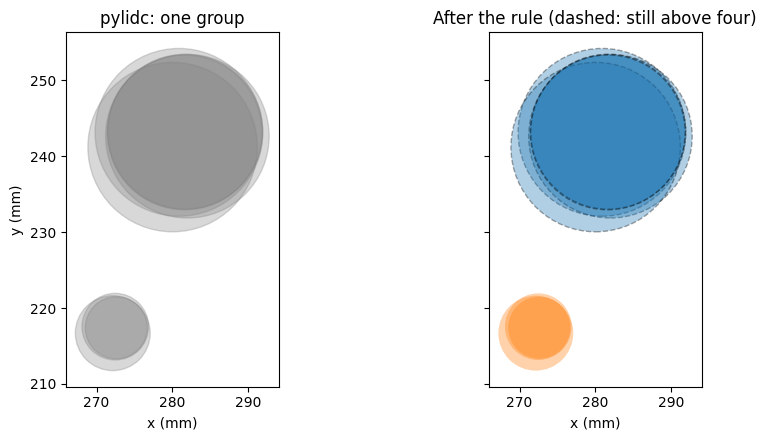

,rating,x_mm,y_mm,z_mm,diameter_mm,group_after_rule
0,4.0,280.9,243.2,-279.8,22.1,1
1,4.0,272.1,216.7,-267.6,9.9,2
2,3.0,272.6,217.4,-268.3,8.2,2
3,5.0,282.0,242.6,-280.7,21.5,1
4,2.0,280.0,241.2,-277.3,22.3,1
5,3.0,281.7,243.2,-279.5,20.4,1
6,2.0,272.5,217.6,-268.4,8.8,2
7,3.0,281.6,243.2,-279.4,20.4,1


In [17]:
def get_oversized_group(patient_id): # Annotations of the first group with more than four annotations of a patient, as given by pylidc.
    pl = import_pylidc()
    for scan in pl.query(pl.Scan).filter(pl.Scan.patient_id == patient_id).all():
        slice_positions = np.asarray(scan.slice_zvals, dtype=float)
        pixel_spacing = float(scan.pixel_spacing)
        for group in scan.cluster_annotations(verbose=False):
            if len(group) > MAX_READERS:
                return [describe_annotation(a, slice_positions, pixel_spacing) for a in group]
    raise LookupError(f"{patient_id} has no group with more than {MAX_READERS} annotations")

try: before = get_oversized_group("LIDC-IDRI-0340")
except Exception as error:
    print(f"Demonstration skipped: {error}")
else:
    after = split_oversized_group(before)
    group_of = {id(a): number for number, group in enumerate(after, start=1) for a in group}

    demo = pd.DataFrame({
        "rating": [a["malignancy"] for a in before],
        "x_mm": [a["centre_mm"][0] for a in before],
        "y_mm": [a["centre_mm"][1] for a in before],
        "z_mm": [a["centre_mm"][2] for a in before],
        "diameter_mm": [2 * a["radius_mm"] for a in before],
        "group_after_rule": [group_of[id(a)] for a in before],
    }).round(1)
    print(f"pylidc: 1 group of {len(before)} annotations")
    for number, group in enumerate(after, start=1):
        note = ", still above four, kept and flagged" if len(group) > MAX_READERS else ""
        print(f"After the rule, group {number}: {len(group)} annotations, mean rating "
              f"{np.mean([a['malignancy'] for a in group]):.2f}, spread {centre_spread(group):.2f} diameters{note}")

    fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for annotation in before:
        x, y, _ = annotation["centre_mm"]
        number = group_of[id(annotation)]
        oversized = len(after[number - 1]) > MAX_READERS
        ax_before.add_patch(plt.Circle((x, y), annotation["radius_mm"], color="grey", alpha=0.3))
        ax_after.add_patch(plt.Circle((x, y), annotation["radius_mm"], facecolor=palette[(number - 1) % 10], alpha=0.35,
                                      edgecolor="black" if oversized else "none", linestyle="--"))
    for axis, title in ((ax_before, "pylidc: one group"), (ax_after, "After the rule (dashed: still above four)")):
        axis.set(title=title, xlabel="x (mm)", aspect="equal")
        axis.autoscale_view()
    ax_before.set_ylabel("y (mm)")
    plt.tight_layout()
    plt.show()

demo if "demo" in globals() else None

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The 8 annotations come from two different lesions, a large one of about 21 mm and a small one of about 9 mm, with their centres roughly 30 mm apart. Before the rule they would have been averaged into a single row that sits between the two lesions and mixes their ratings. After the rule the small lesion is a clean group of three annotations.
  </p>
  <p>
    The five annotations around the large lesion are more than the four radiologists can give, so that group is still above the limit. Its spread is very small (the annotations sit practically on top of each other), which points to one lesion with an extra annotation and not to several lesions. We therefore keep it as one row, marked in 'oversized_group', and we can filter it out later if we want to test the effect.
  </p>
  <p>
    Now the main function. For every scan it asks 'pylidc' for its default groups. Any group with more than four annotations is passed to the rule above. We test that condition directly instead of relying on the message that `pylidc` prints, and at the end we list the scans where `pylidc` did not get to a conclusion, so the problem is never hidden.
  </p>
</div>

In [18]:
if OUTPUT.exists():
    # Built earlier with pylidc (which needs setuptools < 81); loaded instead of rebuilt. Delete the file to rebuild it.
    lidc = pd.read_csv(OUTPUT).query("dataset == 'LIDC'")[SCHEMA].reset_index(drop=True)
    print(f"LIDC rows loaded from {OUTPUT}")
else:
    lidc = build_lidc_table()

print(f"{len(lidc)} nodules in {lidc['patient_id'].nunique()} patients ({lidc['scan_id'].nunique()} CT series)")
print("Annotations per nodule:", lidc["n_readings"].value_counts().sort_index().to_dict())
print(f"Rows produced by the proximity rule: {lidc['reclustered'].sum()}")
print(f"Rows still above four annotations (oversized_group): {lidc['oversized_group'].sum()}")
print(f"Nodules without world x and y (slices not axis aligned): {lidc['x_mm'].isna().sum()}")

LIDC rows loaded from /home/anasofia/labiacd/mass_detect/notebooks/nodule_table.csv
2663 nodules in 875 patients (883 CT series)
Annotations per nodule: {1: 779, 2: 488, 3: 487, 4: 903, 5: 5, 6: 1}
Rows produced by the proximity rule: 26
Rows still above four annotations (oversized_group): 6
Nodules without world x and y (slices not axis aligned): 36


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    To ensure the correction did what we expected, we compare with the counts that Armato et al. (2011) reports for the whole database. The numbers will not match exactly, because the database version and the counting rules are not necessarily the same.
  </p>
</div>

In [19]:
check = pd.DataFrame({
    "nodules of 3 mm or more": [2669, 2651, len(lidc)],
    "nodules with all four readers": [928, 897, int((lidc["n_readings"] == 4).sum())],
}, index=["Armato et al. (2011)", "our first version", "this version"])
check

,nodules of 3 mm or more,nodules with all four readers
Armato et al. (2011),2669,928
our first version,2651,897
this version,2663,903


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Nothing was discarded. The 14 groups where 'pylidc' did not produce a conclusion became 26 rows, and 6 of them still have more than four annotations. They are kept and flagged in 'oversized_group', so the table keeps every nodule and a later analysis can choose to filter them with 'oversized_group'.
  </p>
  <p>
    The LIDC table has 2663 nodules from 875 patients, 6 below the 2669 reported by Armato et al. The number of nodules with four readers is 903, still 25 below the 928 reported. Since the database versions and the counting rules can differ and our rule is an heuristic this comparison is not meant to be exactly the same. The comparison is a sanity check and not a validation: it tells us that we are in the right range and that the correction does not distort the totals.
  </p>
  <p>
    Of the six flagged groups, five are compact (their annotations lie within one diameter of each other), which fits a single nodule with an extra annotation. LIDC IDRI 0055, with a spread of 1.52 diameters, is the one that probably holds several nodules. This is why the sensitivity analysis with and without the 'reclustered' and 'oversized_group' rows is planned.
  </p>
</div>

In [20]:
lidc.to_csv(LIDC_NODULES_FILE, index=False)
print("saved", lidc.shape, "->", LIDC_NODULES_FILE)

saved (2663, 28) -> /home/anasofia/labiacd/mass_detect/notebooks/lidc_nodules.csv


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Individual LIDC Ratings (agreement between radiologists)
  </h3>
  <p>
    Saves every individual LIDC malignancy rating, grouped by nodule, to measure agreement between radiologists. The agreement between two radiologists is the realistic ceiling of any model trained on their ratings. Nodules are grouped with the default pylidc clustering; the groups with more than four annotations are left out of this specific analysis.
  </p>
</div>

In [21]:
# Individual ratings of each radiologist (used later as the agreement ceiling of the model)
if not READER_RATINGS_FILE.exists():
    save_lidc_reader_ratings()
else:
    print("already on disk:", READER_RATINGS_FILE)

already on disk: /home/anasofia/labiacd/mass_detect/data/patches/lidc_reader_ratings.csv
